# Evidencia clase 29/10/26

Filtrado del ECG ($f_s = 1000$ Hz) con un **pasabajos**, comparando tres aproximaciones IIR diseñadas con `sig.iirdesign` (**Butterworth**, **Chebyshev I** y **elíptico**) y un FIR por ventana (`sig.firwin2` con ventana de **Blackman**).

Plantilla:
- Banda de paso: $0$ a $w_p = 20$ Hz, atenuación máxima $a_p = 1$ dB
- Banda de rechazo: desde $w_s = 100$ Hz, atenuación mínima $a_r = 80$ dB

Recordatorio: en un pasabajos $w_p < w_s$; en un pasaaltos $w_p > w_s$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio

## Importo la señal

In [2]:
print(sio.whosmat('../Extra/TS5/ECG_TP4.mat'))
mat_struct = sio.loadmat('../Extra/TS5/ECG_TP4.mat')

fs_ecg = 1000 # Hz
ecg_one_lead = mat_struct['ecg_lead'].flatten() * 1.0
N = len(ecg_one_lead)

[('ecg_lead', (1129116, 1), 'double'), ('qrs_pattern1', (113, 1), 'double'), ('heartbeat_pattern1', (411, 1), 'double'), ('heartbeat_pattern2', (441, 1), 'double'), ('qrs_detections', (1903, 1), 'double')]


## Diseño de los filtros IIR

`iirdesign` elige el orden mínimo que cumple la plantilla para cada aproximación. Uso salida `'sos'` (secciones de segundo orden) por estabilidad numérica.

In [3]:
# lowpass: wp < ws || highpass: wp > ws
wp = 20
ws = 100
ap = 1      # atenuacion de banda de paso
ar = 80     # atenuacion de banda de corte

sos_b = sig.iirdesign(wp, ws, ap, ar, analog=False, ftype="butter", output="sos", fs=fs_ecg)
sos_c = sig.iirdesign(wp, ws, ap, ar, analog=False, ftype="cheby1", output="sos", fs=fs_ecg)
sos_e = sig.iirdesign(wp, ws, ap, ar, analog=False, ftype="ellip", output="sos", fs=fs_ecg)

# Orden de cada filtro (2 por cada sección SOS)
for nombre, sos in [('butter', sos_b), ('cheby1', sos_c), ('ellip', sos_e)]:
    print(f'{nombre}: orden {2 * sos.shape[0]}')

butter: orden 8
cheby1: orden 6
ellip: orden 4


## Filtro FIR

`firwin2` diseña por muestreo en frecuencia + ventana: le paso los puntos de la respuesta deseada (ganancia 1 hasta $w_p$, 0 desde $w_s$ hasta Nyquist) y la ventana de Blackman suaviza los lóbulos. Con 131 coeficientes (orden 130, tipo I) la fase es lineal y el retardo es constante: $(131-1)/2 = 65$ muestras.

In [4]:
taps_win = 131

b_win_blackman = sig.firwin2(taps_win, [0.0, wp, ws, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window='blackman', fs=fs_ecg)

## Respuesta en frecuencia de los cuatro filtros + plantilla

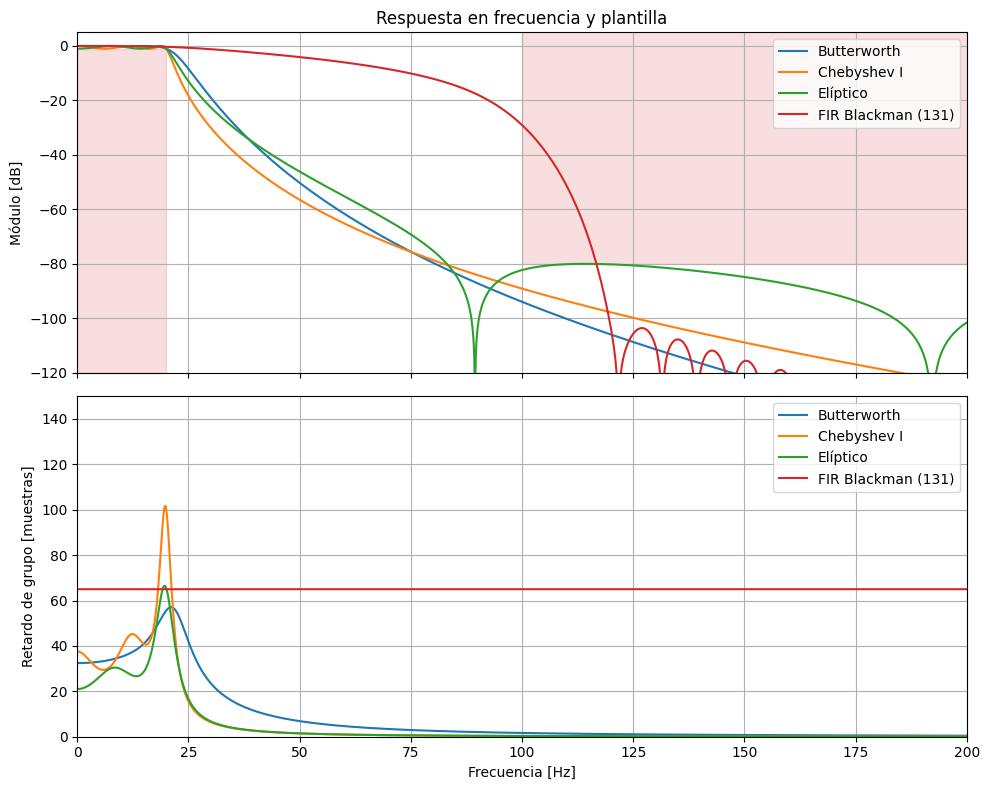

In [5]:
filtros = [('Butterworth', sos_b), ('Chebyshev I', sos_c), ('Elíptico', sos_e)]

fig, (ax_mod, ax_ret) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

for nombre, sos in filtros:
    f, h = sig.freqz_sos(sos, worN=4096, fs=fs_ecg)
    ax_mod.plot(f, 20*np.log10(np.maximum(np.abs(h), 1e-12)), label=nombre)
    # Retardo de grupo solo hasta 200 Hz (más arriba el denominador es casi 0 y no aporta)
    f_gd = f[f <= 200]
    _, gd = sig.group_delay(sig.sos2tf(sos), w=f_gd, fs=fs_ecg)
    ax_ret.plot(f_gd, gd, label=nombre)

f, h = sig.freqz(b_win_blackman, worN=4096, fs=fs_ecg)
ax_mod.plot(f, 20*np.log10(np.maximum(np.abs(h), 1e-12)), label='FIR Blackman (131)')
ax_ret.plot(f, np.full_like(f, (taps_win - 1)/2), label='FIR Blackman (131)')

# Plantilla
ax_mod.fill_between([0, wp], -ap, -200, color='tab:red', alpha=0.15)
ax_mod.fill_between([ws, fs_ecg/2], -ar, 10, color='tab:red', alpha=0.15)
ax_mod.set_ylim(-120, 5)
ax_mod.set_ylabel('Módulo [dB]')
ax_mod.set_title('Respuesta en frecuencia y plantilla')
ax_mod.grid(True)
ax_mod.legend()

ax_ret.set_ylim(0, 150)
ax_ret.set_xlim(0, 200)
ax_ret.set_xlabel('Frecuencia [Hz]')
ax_ret.set_ylabel('Retardo de grupo [muestras]')
ax_ret.grid(True)
ax_ret.legend()

plt.tight_layout()
plt.show()

## Implementación del filtro

Los IIR se aplican con `sosfilt` (filtrado causal, una sola pasada) y el FIR con `lfilter`. Al ser causales, todas las salidas quedan **retrasadas** respecto del ECG original, y en los IIR además con distorsión de fase (retardo no constante).

In [6]:
y_b = sig.sosfilt(sos_b, ecg_one_lead)
y_c = sig.sosfilt(sos_c, ecg_one_lead)
y_e = sig.sosfilt(sos_e, ecg_one_lead)
y_fir = sig.lfilter(b_win_blackman, 1, ecg_one_lead)

## Graficador

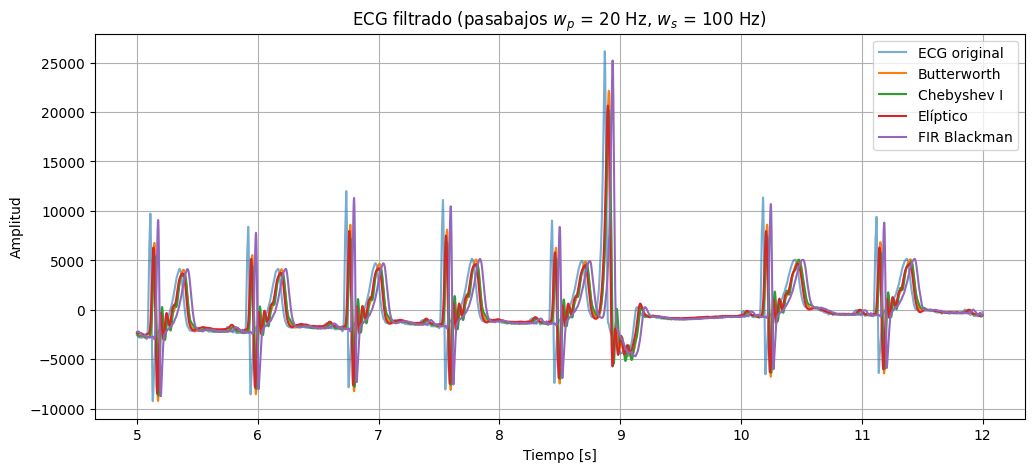

In [7]:
zona = slice(5000, 12000)
t = np.arange(N)[zona] / fs_ecg

plt.figure(figsize=(12, 5))
plt.plot(t, ecg_one_lead[zona], label='ECG original', alpha=0.6)
plt.plot(t, y_b[zona], label='Butterworth')
plt.plot(t, y_c[zona], label='Chebyshev I')
plt.plot(t, y_e[zona], label='Elíptico')
plt.plot(t, y_fir[zona], label='FIR Blackman')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.title('ECG filtrado (pasabajos $w_p$ = 20 Hz, $w_s$ = 100 Hz)')
plt.grid(True)
plt.legend()
plt.show()

## Conclusiones

- Para la misma plantilla, el **elíptico** es el de menor orden, después el **Chebyshev I** y por último el **Butterworth**; el FIR necesita 131 coeficientes.
- Los IIR tienen retardo de grupo no constante (mayor cerca del borde de la banda de paso), lo que deforma levemente los complejos QRS. El FIR tiene fase lineal: retrasa toda la señal 65 muestras (65 ms) sin deformarla.
- Como el corte en 20 Hz es bajo para un ECG, las ondas se suavizan y el QRS pierde algo de amplitud.